In [2]:
import sys
sys.path.append('../')
import matplotlib.pyplot as plt
import numpy as np
from utils import makefolder,get_acronym

eps = 1E-7
rcpsize = 12
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)
import matplotlib.colors as _colors
# print(plt.rcParams.keys())
#np.set_printoptions(precision=None)
markers = ['p','o','h','^','s','*']
_linestyles = ['-','--','dotted']
plot_id = 0

depths = {"deepseek":61,
          "llama":32}

def reduce_list_half_preserve_extremes(lst):
    """
    Reduces the input list to approximately half its original size,
    preserving the first and last elements, and sampling uniformly
    from the intermediate elements.
    
    Parameters:
    -----------
    lst : list
        The input list to reduce.
    
    Returns:
    --------
    list
        A reduced list with approximately half the points,
        preserving the first and last elements.
    """
    N = len(lst)
    if N <= 2:
        return lst.copy()
    
    half_N = max(N // 2, 2)
    num_points_to_sample = half_N - 2
    
    new_lst = [lst[0]]
    
    if num_points_to_sample > 0:
        # Calculate the indices to sample from intermediates
        step = (N - 2) / (num_points_to_sample + 1)
        intermediate_indices = [int(round(1 + i * step)) for i in range(num_points_to_sample)]
        new_lst.extend([lst[i] for i in intermediate_indices])
    
    new_lst.append(lst[-1])
    return new_lst


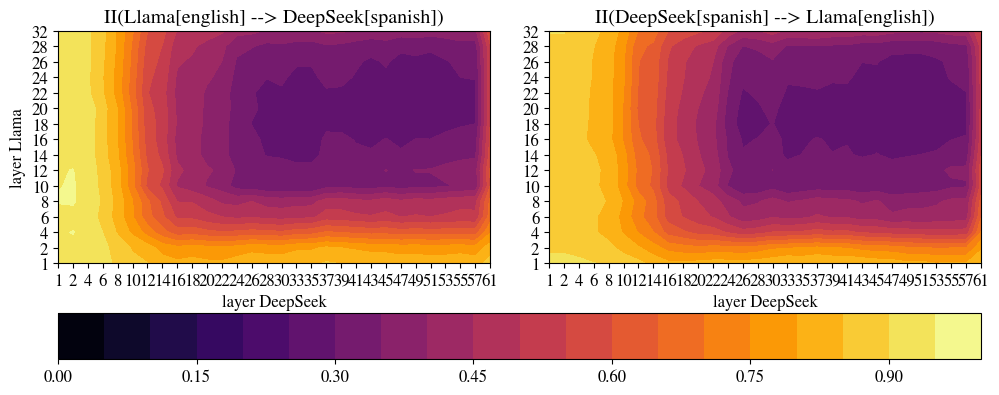

II_AB[-1,-1]=0.5939280986785889
II_BA[-1,-1]=0.5604098439216614
II_AB[-1,-1] - II_BA[-1,-1]=0.03351825475692749

np.min(II_AB)=0.26809024810791016
np.min(II_BA)=0.25453829765319824
np.min(II_AB)-np.min(II_BA)=0.013551950454711914


In [49]:
mask = 2
language_pairs = [('english','spanish'),
                  # ('english','italian'),
                  # ('spanish','italian'),
                  # ('german','hungarian'),
                  ]
layers_llama = reduce_list_half_preserve_extremes(list(range(1,depths['llama']+1)))
layers_deepseek = reduce_list_half_preserve_extremes(list(range(1,depths['deepseek']+1)))
n_files = 200
figsfolder = makefolder(base=f'./results/figs/translations/',
                        create_folder=True,
                        n_files=n_files,
                        )

batch_size = 10 
Ns = batch_size*n_files

n_tokens_list = [10]
k_list = [10]
min_token_length = 20
Nbits_list = [1]

seed_list = [0]
batch_shuffle = 0

modelA = 'llama'
modelB = 'deepseek'
fig, ax = plt.subplots(figsize=(10, 4), ncols=2)

aux_A = 'source'
aux_B = 'target'

for Nbits_id, Nbits in enumerate(Nbits_list):
  for seed_id, seed in enumerate(seed_list):
    for k_id,k in enumerate(k_list):
      for avg in [0]:
        avg_tokens_II = avg
        avg_tokens_A = avg_tokens_II
        for n_tokens_id,n_tokens in enumerate(n_tokens_list):
            for language_pair_id, language_pair in enumerate(language_pairs):

              (languageA,languageB) = language_pair
              II_folder = makefolder(base=f'./results/santiago/',
                                    batch_shuffle=batch_shuffle,
                                    modelA=modelA,
                                    modelB=modelB,
                                    aux_A=aux_A,
                                    aux_B=aux_B,
                                    n_files=n_files,
                                    min_token_length=min_token_length,
                                    languageA=languageA,
                                    languageB=languageB,
                                    mask=mask,
                                    k=k,
                                    Nbits=Nbits,
                                    seed=seed,
                                    )

              # alignment = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_A}_alignment.npy')
              II_AB = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_II}_AB.npy')

              II_BA = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_II}_BA.npy')

              vmin = min(II_AB.min(), II_BA.min())
              vmax = max(II_AB.max(), II_BA.max())
              levels = 100+1

              vmin = 0
              vmax = 1 
              levels = 20+1
              levels = np.linspace(vmin, vmax, levels)
              fig.tight_layout()


              im0 = ax[0].contourf(II_AB, levels=levels, cmap='inferno')
              im1 = ax[1].contourf(II_BA, levels=levels, cmap='inferno')
              cbar = fig.colorbar(im0, ax=ax, orientation='horizontal', pad=0.15)

_aux_A = languageA if aux_A == 'source' else languageB
_aux_B = languageA if aux_B == 'source' else languageB
ax[0].set_title(f'II(Llama[{_aux_A}] --> DeepSeek[{_aux_B}])')
ax[0].set_ylabel(f'layer Llama')
ax[1].set_title(f'II(DeepSeek[{_aux_B}] --> Llama[{_aux_A}])')
ax[0].set_xlabel(f'layer DeepSeek')
ax[1].set_xlabel(f'layer DeepSeek')
# Set ticks for x and y axes on each subplot
ax[0].set_xticks(np.arange(len(layers_deepseek)))
ax[0].set_xticklabels(layers_deepseek)
ax[0].set_yticks(np.arange(len(layers_llama)))
ax[0].set_yticklabels(layers_llama)

ax[1].set_xticks(np.arange(len(layers_deepseek)))
ax[1].set_xticklabels(layers_deepseek)
ax[1].set_yticks(np.arange(len(layers_llama)))
ax[1].set_yticklabels(layers_llama)

plt.show()
# fig.savefig(f'{figsfolder}translations_diagonal_{n_tokens}.pdf',
#               bbox_inches='tight',
#               )
print(f'{II_AB[-1,-1]=}')
print(f'{II_BA[-1,-1]=}')
print(f'{II_AB[-1,-1] - II_BA[-1,-1]=}')
print('')
print(f'{np.min(II_AB)=}')
print(f'{np.min(II_BA)=}')
print(f'{np.min(II_AB)-np.min(II_BA)=}')

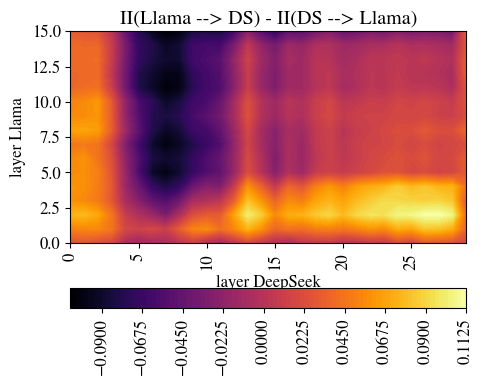

In [42]:
# A = Llama
# B = DeepSeek

X = II_AB-II_BA # <0 means Llama more informative than DeepSeek
fig,ax = plt.subplots(figsize=(5, 4))
im0 = ax.contourf(X,cmap='inferno',levels=100)
cbar = fig.colorbar(
    im0,
    ax=ax,
    orientation='horizontal',
    location='bottom',   # <— force it below
    pad=0.15,             # space between axes and colorbar
)
ax.set_title(f'II(Llama --> DS) - II(DS --> Llama)')
ax.set_xlabel(f'layer DeepSeek')
ax.set_ylabel(f'layer Llama')

for label in ax.get_xticklabels():
  label.set_rotation(90)
for label in cbar.ax.get_xticklabels():
  label.set_rotation(90)


plt.show()

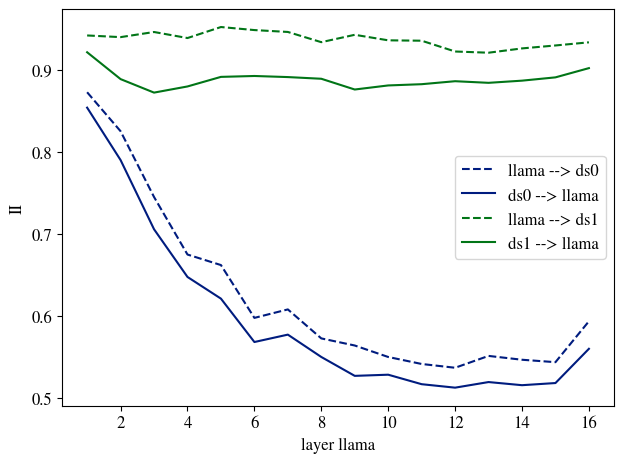

In [11]:
layer_ids_ds = [-1,0]
# layer_ids_ds = [20,50]
# layer_ids_ds = [30,40]
fig,ax = plt.subplots(1)

for l_index,layer_id_ds in enumerate(layer_ids_ds):
  ax.plot(np.arange(1,II_AB.shape[0]+1),
          II_AB[:,layer_id_ds],
          label=f'llama --> ds{layer_id_ds+1}',
          color=colors[l_index],
          linestyle='--'
          )
  ax.plot(np.arange(1,II_AB.shape[0]+1),
          II_BA[:,layer_id_ds],
          label=f'ds{layer_id_ds+1} --> llama',
          linestyle='-',
          color=colors[l_index],
          )
ax.legend()
ax.set_ylabel('II')
ax.set_xlabel('layer llama')
plt.show()

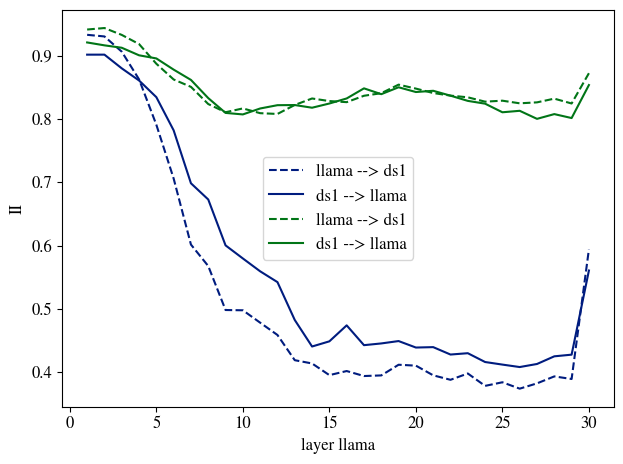

In [12]:
layer_ids_llama = [-1,0]
# layer_ids_ds = [20,50]
# layer_ids_ds = [30,40]
fig,ax = plt.subplots(1)

for l_index,layer_id_llama in enumerate(layer_ids_llama):
  ax.plot(np.arange(1,II_AB.shape[1]+1),
          II_AB[layer_id_llama,:],
          label=f'llama --> ds{layer_id_ds+1}',
          color=colors[l_index],
          linestyle='--'
          )
  ax.plot(np.arange(1,II_AB.shape[1]+1),
          II_BA[layer_id_llama,:],
          label=f'ds{layer_id_ds+1} --> llama',
          linestyle='-',
          color=colors[l_index],
          )
ax.legend()
ax.set_ylabel('II')
ax.set_xlabel('layer llama')
plt.show()

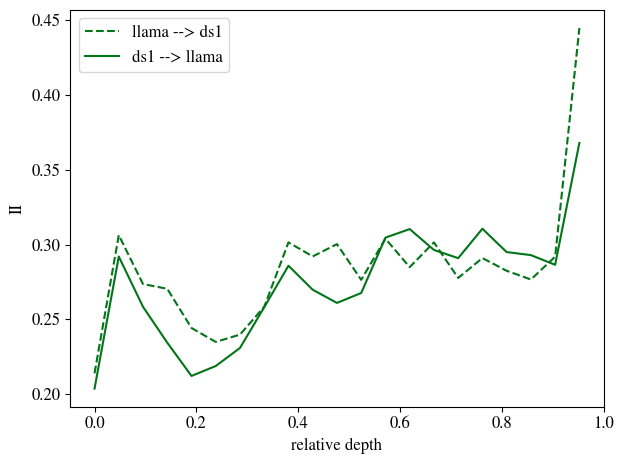

In [47]:
fig,ax = plt.subplots(1)

ids = np.arange(0,1+eps,0.05) 
ids_A = (np.round(31 * ids)).astype(int)
ids_B = (np.round(60 * ids)).astype(int)


ax.plot(np.arange(ids.shape[0]) / ids.shape[0],
          II_AB[ids_A,ids_B],
          label=f'llama --> ds{layer_id_ds+1}',
          color=colors[l_index],
          linestyle='--'
          )
ax.plot(np.arange(ids.shape[0]) / ids.shape[0],
        II_BA[ids_A,ids_B],
        label=f'ds{layer_id_ds+1} --> llama',
        linestyle='-',
        color=colors[l_index],
        )
ax.legend()
ax.set_ylabel('II')
ax.set_xlabel('relative depth')
plt.show()

II_AB[-1,-1]=0.5939280986785889
II_BA[-1,-1]=0.5604098439216614
II_AB[-1,-1] - II_BA[-1,-1]=0.03351825475692749
